In [1]:
# ============================================================
# RCNN FINAL PIPELINE (VOC2012) — COMPARISON READY
# Includes: Training, Evaluation, Timing, Speed, Visualization
# ============================================================

import torch, time, cv2, os
import numpy as np
import pandas as pd
from pathlib import Path
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# ---------------- SETTINGS ----------------
torch.backends.cudnn.benchmark = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

VOC_ROOT = "/kaggle/input/datasets/huanghanchina/pascal-voc-2012/VOC2012"
OUTPUT_DIR = "outputs/rcnn"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

EPOCHS = 5
BATCH_SIZE = 2

print("="*60)
print("RCNN COMPARISON PIPELINE STARTED")
print("Device:", DEVICE)
print("="*60)


RCNN COMPARISON PIPELINE STARTED
Device: cuda


In [2]:
# ---------------- LOAD IDS ----------------
def load_ids(txt):
    with open(txt) as f:
        return [x.strip() for x in f]

train_ids = load_ids(VOC_ROOT + "/ImageSets/Main/train.txt")[:2000]
val_ids   = load_ids(VOC_ROOT + "/ImageSets/Main/val.txt")[:500]

print("Train:", len(train_ids), "Val:", len(val_ids))


Train: 2000 Val: 500


In [3]:
# ---------------- DATASET ----------------
class VOCDataset(Dataset):
    def __init__(self, root, ids):
        self.root = Path(root)
        self.ids = ids
        self.img_dir = self.root / "JPEGImages"
        self.ann_dir = self.root / "Annotations"

        self.classes = [
            "aeroplane","bicycle","bird","boat","bottle","bus","car","cat",
            "chair","cow","diningtable","dog","horse","motorbike","person",
            "pottedplant","sheep","sofa","train","tvmonitor"
        ]
        self.class2idx = {c:i+1 for i,c in enumerate(self.classes)}

        print("Caching annotations...")
        self.cache = []
        for img_id in self.ids:
            root = ET.parse(self.ann_dir / f"{img_id}.xml").getroot()
            boxes, labels = [], []

            for obj in root.findall("object"):
                name = obj.find("name").text
                if name not in self.class2idx: continue

                b = obj.find("bndbox")
                x1 = float(b.find("xmin").text)
                y1 = float(b.find("ymin").text)
                x2 = float(b.find("xmax").text)
                y2 = float(b.find("ymax").text)

                if x2 > x1 and y2 > y1:
                    boxes.append([x1,y1,x2,y2])
                    labels.append(self.class2idx[name])

            self.cache.append((boxes, labels))

    def __len__(self): return len(self.ids)

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        img = read_image(str(self.img_dir / f"{img_id}.jpg")).float()/255.0

        boxes, labels = self.cache[idx]

        if len(boxes) == 0:
            boxes = torch.zeros((0,4))
            labels = torch.zeros((0,), dtype=torch.int64)

        return img, {
            "boxes": torch.tensor(boxes, dtype=torch.float32),
            "labels": torch.tensor(labels, dtype=torch.int64)
        }

def collate_fn(batch): return tuple(zip(*batch))


In [4]:
# ---------------- MODEL ----------------
def get_model():
    print("Loading model...")
    model = fasterrcnn_resnet50_fpn_v2(weights="DEFAULT")
    in_f = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_f, 21)
    model.transform.min_size = (400,)
    return model

In [5]:

# ---------------- TRAIN ----------------
def train_one_epoch(model, loader, optimizer):
    model.train()
    scaler = torch.cuda.amp.GradScaler()
    total_loss = 0

    for i, (imgs, targets) in enumerate(loader):
        if i % 100 == 0:
            print("Step", i, "/", len(loader))

        imgs = [img.to(DEVICE) for img in imgs]
        targets = [{k:v.to(DEVICE) for k,v in t.items()} for t in targets]

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            loss = sum(model(imgs, targets).values())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    return total_loss / len(loader)
    

In [6]:
# ---------------- EVALUATION ----------------
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    metric = MeanAveragePrecision().to(DEVICE)

    for imgs, targets in loader:
        imgs = [img.to(DEVICE) for img in imgs]
        preds = model(imgs)

        preds = [{k:v.cpu() for k,v in p.items()} for p in preds]
        targets = [{k:v.cpu() for k,v in t.items()} for t in targets]

        metric.update(preds, targets)

    return metric.compute()

# ---------------- SPEED ----------------
@torch.no_grad()
def measure_speed(model, loader):
    model.eval()
    times = []

    for i, (imgs, _) in enumerate(loader):
        if i > 30: break
        imgs = [img.to(DEVICE) for img in imgs]

        torch.cuda.synchronize()
        t0 = time.time()
        _ = model(imgs)
        torch.cuda.synchronize()

        times.append(time.time() - t0)

    avg = np.mean(times)
    return avg*1000, 1/avg

# ---------------- VIS ----------------
def visualize(model, dataset):
    print("Saving predictions...")
    model.eval()

    for i in range(5):
        img,_ = dataset[i]
        pred = model([img.to(DEVICE)])[0]

        im = img.permute(1,2,0).numpy()

        for b,s in zip(pred["boxes"], pred["scores"]):
            if s < 0.5: continue
            x1,y1,x2,y2 = map(int,b)
            cv2.rectangle(im,(x1,y1),(x2,y2),(0,1,0),2)

        plt.imshow(im)
        plt.axis("off")
        plt.savefig(f"{OUTPUT_DIR}/pred_{i}.png")

Caching annotations...
Caching annotations...
Loading model...
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 194MB/s]


Epoch 1


/tmp/ipykernel_24/16917038.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Step 0 / 1000


/tmp/ipykernel_24/16917038.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Step 100 / 1000
Step 200 / 1000
Step 300 / 1000
Step 400 / 1000
Step 500 / 1000
Step 600 / 1000
Step 700 / 1000
Step 800 / 1000
Step 900 / 1000
Loss: 0.4873
mAP50: 0.6518
Epoch 2
Step 0 / 1000
Step 100 / 1000
Step 200 / 1000
Step 300 / 1000
Step 400 / 1000
Step 500 / 1000
Step 600 / 1000
Step 700 / 1000
Step 800 / 1000
Step 900 / 1000
Loss: 0.319
mAP50: 0.6816
Epoch 3
Step 0 / 1000
Step 100 / 1000
Step 200 / 1000
Step 300 / 1000
Step 400 / 1000
Step 500 / 1000
Step 600 / 1000
Step 700 / 1000
Step 800 / 1000
Step 900 / 1000
Loss: 0.2458
mAP50: 0.6786
Epoch 4
Step 0 / 1000
Step 100 / 1000
Step 200 / 1000
Step 300 / 1000
Step 400 / 1000
Step 500 / 1000
Step 600 / 1000
Step 700 / 1000
Step 800 / 1000
Step 900 / 1000
Loss: 0.1925
mAP50: 0.6869
Epoch 5
Step 0 / 1000
Step 100 / 1000
Step 200 / 1000
Step 300 / 1000
Step 400 / 1000
Step 500 / 1000
Step 600 / 1000
Step 700 / 1000
Step 800 / 1000
Step 900 / 1000
Loss: 0.1637
mAP50: 0.6934
Saving predictions...
DONE
Outputs saved in: outputs/rcnn


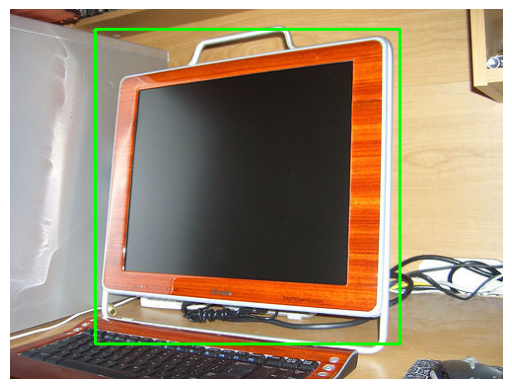

In [7]:



# ---------------- RUN ----------------
train_ds = VOCDataset(VOC_ROOT, train_ids)
val_ds   = VOCDataset(VOC_ROOT, val_ids)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, collate_fn=collate_fn)
val_dl   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, collate_fn=collate_fn)

model = get_model().to(DEVICE)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)

history = []
epoch_times = []

for epoch in range(EPOCHS):
    print("="*50)
    print("Epoch", epoch+1)

    start = time.time()

    loss = train_one_epoch(model, train_dl, optimizer)
    res = evaluate(model, val_dl)

    epoch_time = time.time() - start
    epoch_times.append(epoch_time)

    map50 = res["map_50"].item()
    map5095 = res["map"].item()

    print("Loss:", round(loss,4))
    print("mAP50:", round(map50,4))

    history.append({
        "epoch": epoch+1,
        "map50": map50,
        "map5095": map5095,
        "epoch_time_sec": epoch_time
    })

# ---------------- SAVE METRICS ----------------
pd.DataFrame(history).to_csv(f"{OUTPUT_DIR}/metrics.csv", index=False)

ms, fps = measure_speed(model, val_dl)
pd.DataFrame([{
    "latency_ms": ms,
    "fps": fps
}]).to_csv(f"{OUTPUT_DIR}/speed.csv", index=False)

visualize(model, val_ds)

print("="*60)
print("DONE")
print("Outputs saved in:", OUTPUT_DIR)
print("="*60)